# 02 — MDP de la batería: Q-learning vs. iteración de valor vs. líneas base

Implementación propia (clases 4 y 5). El código está en `src/entorno.py` y `src/politicas.py`.

## Formulación

| Elemento | Definición |
|---|---|
| Estado $s$ | $(\text{hora},\ \text{nivel SOC},\ \text{nivel de precio})$ |
| Nivel de precio | bajo / medio / alto según $p_t / \bar p_{\text{día anterior}}$ (< 0.85, > 1.15). Es **causal**: no usa el futuro |
| Acciones $a$ | descargar, esperar, cargar (una hora a potencia nominal) |
| Recompensa $R(s,a)$ | cargar: $-p_t\,e$ · descargar: $+p_t\,e\,\eta$ · esperar: 0  (COP) |
| Episodio | 1 día (24 pasos), batería inicia vacía, $\gamma = 1$ |

La suma de recompensas es el **ahorro frente a no tener batería** para un usuario que paga precio de bolsa.

## Políticas comparadas

| Política | Tipo |
|---|---|
| **Q-learning** | model-free, $\epsilon$-greedy, $\alpha(s,a)=1/N(s,a)^{0.7}$ (clase 5) |
| **Iteración de valor** | model-based: estima $T(s,a,s')$ y $R(s,a)$ de los datos y resuelve Bellman (clase 4) |
| Horario fijo | **línea base ingenua**: carga en las horas más baratas del perfil promedio, descarga en las más caras |
| Aleatoria | línea base (random walk de la clase 5) |
| Oráculo | **referencia / cota superior**: conoce los 24 precios del día (información perfecta) |

**Métrica:** ahorro total en COP en el periodo de prueba y **% del oráculo** capturado.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

In [2]:
import random
import datos, politicas
from entorno import BatteryEnv, ACTIONS

M = datos.price_matrix(datos.load_prices())
train, test = M[M.index <= "2025-12-31"], M[M.index > "2025-12-31"]

CAP, POW, EFF = 10.0, 2.5, 0.90          # batería de 10 kWh, 2.5 kW → 4 h para llenarse
env_train = BatteryEnv(train, CAP, POW, EFF)
env_test = BatteryEnv(test, CAP, POW, EFF)
print("Niveles de SOC:", env_train.n_levels + 1, "| energía por paso:", env_train.e_step, "kWh")
print("Número de estados:", len(env_train.states()))

Niveles de SOC: 5 | energía por paso: 2.5 kWh
Número de estados: 360


## 1. Prueba rápida del ambiente

In [3]:
state = env_train.reset(0)
print("Estado inicial:", state, "| acciones válidas:", [ACTIONS[a] for a in env_train.possible_actions(state[1])])
for a in [2, 2, 1, 0]:
    next_state, reward, done = env_train.step(a)
    print(f"{ACTIONS[a]:>9} → s'={next_state}  r={reward:8.1f} COP  done={done}")

Estado inicial: (0, 0, 1) | acciones válidas: ['esperar', 'cargar']
   cargar → s'=(1, 1, 1)  r=  -629.8 COP  done=False
   cargar → s'=(2, 2, 1)  r=  -629.8 COP  done=False
  esperar → s'=(3, 2, 2)  r=     0.0 COP  done=False
descargar → s'=(4, 1, 2)  r=   634.3 COP  done=False


## 2. Q-learning

Dos ajustes frente al CheeseWorld de clase, justificados por los experimentos:
1. **Tasa de aprendizaje decreciente** $\alpha = 1/N(s,a)^{0.7}$: con $\alpha$ fijo la Q-table oscila por el ruido de los precios.
2. **Recompensa relativa al entrenar** ($r / \bar p_{\text{día anterior}}$): los días de El Niño (precios 5× mayores)
   dominaban el aprendizaje. Escalar un día completo no cambia qué hora conviene más.

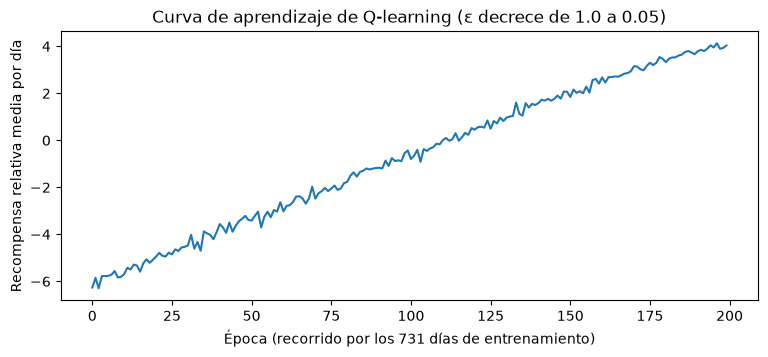

In [4]:
env_q = BatteryEnv(train, CAP, POW, EFF, relative_reward=True)
agent = politicas.QLearningAgent(env_q)
history = agent.train(epochs=200, seed=42)

plt.figure(figsize=(9, 3.5))
plt.plot(history)
plt.xlabel("Época (recorrido por los 731 días de entrenamiento)")
plt.ylabel("Recompensa relativa media por día")
plt.title("Curva de aprendizaje de Q-learning (ε decrece de 1.0 a 0.05)")
plt.show()

## 3. Iteración de valor (model-based)

Con los datos de entrenamiento se estiman $P(\text{nivel}'\mid \text{hora},\text{nivel})$ y
$E[p\mid\text{hora},\text{nivel}]$. Como el horizonte es finito (24 h), Bellman se resuelve por
inducción hacia atrás: $V_{24}=0$, $V_h(s)=\max_a\big[R(s,a)+\sum_{s'}T(s,a,s')V_{h+1}(s')\big]$.

In [5]:
vi = politicas.ValueIterationPolicy(env_train).fit_model().value_iteration()
print("Matriz de transición del nivel de precio a las 17 h (filas: bajo/medio/alto):")
print(pd.DataFrame(vi.P[17], index=["bajo", "medio", "alto"], columns=["bajo", "medio", "alto"]).round(2))

Matriz de transición del nivel de precio a las 17 h (filas: bajo/medio/alto):
       bajo  medio  alto
bajo    0.3   0.30  0.39
medio   0.0   0.78  0.22
alto    0.0   0.00  1.00


## 4. Comparación en el periodo de prueba (2026, datos no vistos)

In [6]:
policies = {
    "q_learning": agent,
    "iteracion_valor": vi,
    "horario_fijo": politicas.FixedSchedulePolicy(env_train),
    "aleatoria": politicas.RandomPolicy(),
    "oraculo": politicas.OraclePolicy(),
}
table, details = politicas.compare_policies(policies, env_test)
table.round(1)

,politica,ahorro_total_cop,ahorro_diario_cop,ciclos_equivalentes,dias,pct_del_oraculo
clave,,,,,,
q_learning,Q-learning,484607.3,1594.1,346.0,304,74.6
iteracion_valor,Iteración de valor,492820.0,1621.1,301.5,304,75.8
horario_fijo,Horario fijo (ingenua),469598.7,1544.7,304.0,304,72.3
aleatoria,Aleatoria,-981479.9,-3228.6,484.2,304,-151.1
oraculo,Oráculo (info. perfecta),649756.1,2137.4,277.5,304,100.0


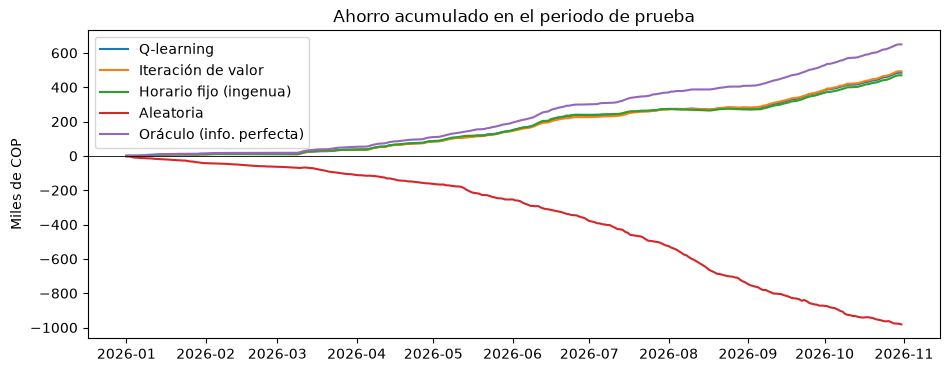

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
for key, df in details.items():
    ax.plot(df.groupby("fecha")["recompensa"].sum().cumsum() / 1000, label=policies[key].name)
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("Miles de COP"); ax.legend()
ax.set_title("Ahorro acumulado en el periodo de prueba")
plt.show()

## 5. Robustez: varias semillas y varios tamaños de batería

Q-learning es estocástico. Se reporta media ± desviación estándar en 5 semillas.

In [8]:
rows = []
for cap, pw in [(10, 2.5), (10, 5.0), (10, 1.25)]:
    etr, ete = BatteryEnv(train, cap, pw, EFF), BatteryEnv(test, cap, pw, EFF)
    eq = BatteryEnv(train, cap, pw, EFF, relative_reward=True)
    oracle = politicas.summarize(politicas.simulate(politicas.OraclePolicy(), ete), ete)["ahorro_total_cop"]
    pct = lambda pol: 100 * politicas.summarize(politicas.simulate(pol, ete), ete)["ahorro_total_cop"] / oracle
    q_scores = []
    for seed in range(5):
        a = politicas.QLearningAgent(eq); a.train(epochs=200, seed=seed)
        q_scores.append(pct(a))
    rows.append({
        "bateria": f"{cap:g} kWh / {pw:g} kW",
        "Q-learning (media ± std)": f"{np.mean(q_scores):.1f} ± {np.std(q_scores):.1f}",
        "Iteración de valor": round(pct(politicas.ValueIterationPolicy(etr).fit_model().value_iteration()), 1),
        "Horario fijo": round(pct(politicas.FixedSchedulePolicy(etr)), 1),
        "Aleatoria": round(pct(politicas.RandomPolicy()), 1),
    })
robust = pd.DataFrame(rows).set_index("bateria")
(datos.ROOT / "resultados").mkdir(exist_ok=True)
robust.to_csv(datos.ROOT / "resultados" / "robustez_politicas.csv")
print("% del ahorro del oráculo capturado en 2026:")
robust

% del ahorro del oráculo capturado en 2026:


,Q-learning (media ± std),Iteración de valor,Horario fijo,Aleatoria
bateria,,,,
10 kWh / 2.5 kW,77.7 ± 1.7,75.8,72.3,-146.6
10 kWh / 5 kW,76.8 ± 3.3,76.6,70.6,-126.1
10 kWh / 1.25 kW,81.3 ± 2.1,80.5,73.0,-148.5


## 6. ¿Qué aprendió el agente?

Política greedy de Q-learning a las horas clave (SOC = 0, nivel de precio medio) y patrón horario en la prueba.

In [9]:
pattern = pd.crosstab(details["q_learning"]["hora"], details["q_learning"]["accion"], normalize="index") * 100
pattern.round(0).T

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
accion,,,,,,,,,,,,,,,,,,,,,
cargar,94.0,37.0,38.0,92.0,4.0,7.0,2.0,10.0,15.0,53.0,...,0.0,0.0,2.0,60.0,0.0,0.0,0.0,0.0,0.0,0.0
descargar,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,15.0,74.0,0.0,99.0,100.0,100.0,62.0,2.0,0.0
esperar,6.0,63.0,62.0,8.0,94.0,93.0,98.0,90.0,85.0,47.0,...,100.0,85.0,24.0,40.0,1.0,0.0,0.0,38.0,98.0,100.0


In [10]:
# π(s) = argmax_a Q(s,a) para batería vacía y llena
greedy = pd.DataFrame(
    [[ACTIONS[agent.act(env_test, (h, soc, lvl))] for lvl in range(3)]
     for h in range(24) for soc in [0, env_test.n_levels]],
    index=pd.MultiIndex.from_product([range(24), ["vacía", "llena"]], names=["hora", "batería"]),
    columns=["precio bajo", "precio medio", "precio alto"],
)
greedy.loc[[1, 3, 6, 12, 17, 18, 19, 20, 22]]

precio bajo precio medio precio alto
hora batería                                     
1    vacía        cargar       cargar     esperar
     llena     descargar    descargar   descargar
3    vacía        cargar       cargar     esperar
     llena     descargar      esperar   descargar
6    vacía        cargar       cargar     esperar
     llena       esperar      esperar   descargar
12   vacía        cargar       cargar      cargar
     llena       esperar      esperar   descargar
17   vacía        cargar       cargar      cargar
     llena       esperar      esperar   descargar
18   vacía        cargar       cargar      cargar
     llena       esperar    descargar   descargar
19   vacía       esperar      esperar     esperar
     llena     descargar    descargar   descargar
20   vacía       esperar      esperar     esperar
     llena     descargar    descargar   descargar
22   vacía       esperar      esperar     esperar
     llena     descargar    descargar   descargar

## 7. Conclusiones y limitaciones

- Las políticas aprendidas (Q-learning e iteración de valor) superan a la **aleatoria** por mucho y
  igualan o superan al **horario fijo**. Capturan alrededor de 3/4 del ahorro del **oráculo**.
- La ventaja sobre el horario fijo es moderada porque el perfil diario del precio de bolsa en Colombia es
  muy regular (pico 18–21 h). El RL gana porque **reacciona al nivel de precio**: no carga de madrugada
  si el precio está alto, y hace un segundo ciclo parcial por la tarde (descarga 15–16 h, recarga 17 h).
  Esto se ve en el patrón horario y en sus ciclos equivalentes (346 frente a 304).
- **Limitaciones:** (1) estado discretizado en 3 niveles de precio; (2) no se modela degradación ni
  tarifas reales de un usuario regulado, que no paga el precio de bolsa directamente; (3) la batería
  inicia vacía cada día; (4) se usa el precio ex-post como si fuera conocido en la hora de decisión;
  (5) no se usa radiación solar (IDEAM), que sería el siguiente paso.